# RoadVision AI — Data Analysis & Visualization

## Objectives
- Analyze class distribution across training and validation sets.
- Study normalized bounding-box sizes and aspect ratios.
- Analyze the number of objects per image.
- Quantify potential class imbalance.
- Export analysis reports and visualizations.

**Important:** This notebook is read-only. It does not modify the original or cleaned dataset.


## 1. Configuration and prepared dataset paths

Use the prepared dataset produced by `04_dataset_preparation.ipynb`. The original `trafic_data/` directory is only used to read the dataset YAML configuration.


In [1]:
import os
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

# Original dataset: read-only reference
DEFAULT_CACHE = Path.home() / ".cache" / "kagglehub" / "datasets" / "ashfakyeafi" / "road-vehicle-images-dataset" / "versions" / "2"
DATASET_VERSION_ROOT = Path(os.getenv("ROADVISION_DATASET_VERSION_ROOT", str(DEFAULT_CACHE)))
ORIGINAL_ROOT = Path(os.getenv("ROADVISION_ORIGINAL_ROOT", str(DATASET_VERSION_ROOT / "trafic_data")))

# Prepared dataset from notebook 04
CLEAN_ROOT = Path(os.getenv("ROADVISION_CLEANED_ROOT", str(DATASET_VERSION_ROOT / "roadvision_cleaned")))

# Analysis outputs (inside the prepared dataset; source data remains untouched)
REPORT_DIR = CLEAN_ROOT / "reports"
FIGURE_DIR = CLEAN_ROOT / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "valid"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

print("Original dataset exists:", ORIGINAL_ROOT.exists())
print("Cleaned dataset exists:", CLEAN_ROOT.exists())
print("Reports directory:", REPORT_DIR)
print("Figures directory:", FIGURE_DIR)

assert CLEAN_ROOT.exists(), (
    "Cleaned dataset not found. Check CLEAN_ROOT against the output path "
    "configured in 04_dataset_preparation.ipynb."
)

Original dataset exists: True
Cleaned dataset exists: True
Reports directory: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/reports
Figures directory: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/figures


## 2. Load class names and YOLO annotations

Load class names from the source YAML, then read labels from `roadvision_cleaned/`. Each YOLO annotation row is expected to contain:

`class_id x_center y_center width height`

Coordinates and dimensions are normalized to the range 0–1. This notebook reports unexpected rows rather than changing the dataset.


In [2]:
# Find the YAML configuration in the original dataset.
yaml_path = ORIGINAL_ROOT / "data_1.yaml"
if not yaml_path.exists():
    yaml_path = ORIGINAL_ROOT.parent / "data_1.yaml"

assert yaml_path.exists(), f"Dataset YAML not found: {yaml_path}"

with open(yaml_path, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

raw_names = config["names"]
if isinstance(raw_names, dict):
    CLASS_NAMES = [raw_names[i] if i in raw_names else raw_names[str(i)]
                   for i in range(int(config["nc"]))]
else:
    CLASS_NAMES = list(raw_names)

NC = int(config["nc"])
assert len(CLASS_NAMES) == NC, (
    f"Expected {NC} class names, found {len(CLASS_NAMES)}"
)

print(f"Number of classes: {NC}")
print("\nClass mapping:")
for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id:2d}: {class_name}")

Number of classes: 21

Class mapping:
 0: ambulance
 1: army vehicle
 2: auto rickshaw
 3: bicycle
 4: bus
 5: car
 6: garbagevan
 7: human hauler
 8: minibus
 9: minivan
10: motorbike
11: pickup
12: policecar
13: rickshaw
14: scooter
15: suv
16: taxi
17: three wheelers -CNG-
18: truck
19: van
20: wheelbarrow


In [3]:
# Verify the prepared dataset structure and actual counts.
split_summary = []

for split in SPLITS:
    image_dir = CLEAN_ROOT / split / "images"
    label_dir = CLEAN_ROOT / split / "labels"

    image_files = (
        sorted(p for p in image_dir.iterdir()
               if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        if image_dir.exists() else []
    )
    label_files = sorted(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"\n{split.upper()}")
    print("Images directory exists:", image_dir.exists())
    print("Labels directory exists:", label_dir.exists())
    print("Images:", len(image_files))
    print("Label files:", len(label_files))

    split_summary.append({
        "split": split,
        "images": len(image_files),
        "label_files": len(label_files),
        "images_dir_exists": image_dir.exists(),
        "labels_dir_exists": label_dir.exists(),
    })

assert all((CLEAN_ROOT / s / "images").exists() for s in SPLITS), \
    "At least one prepared images directory is missing."
assert all((CLEAN_ROOT / s / "labels").exists() for s in SPLITS), \
    "At least one prepared labels directory is missing."

pd.DataFrame(split_summary)


TRAIN
Images directory exists: True
Labels directory exists: True
Images: 2703
Label files: 2703

VALID
Images directory exists: True
Labels directory exists: True
Images: 300
Label files: 300


,split,images,label_files,images_dir_exists,labels_dir_exists
0,train,2703,2703,True,True
1,valid,300,300,True,True


### Build a single annotation DataFrame

The annotation table contains one row per valid parsed bounding box. A separate image-level table includes every image, including images with zero annotated objects, so object counts are not biased by empty label files.


In [4]:
annotation_rows = []
image_rows = []
parse_issues = []

for split in SPLITS:
    image_dir = CLEAN_ROOT / split / "images"
    label_dir = CLEAN_ROOT / split / "labels"

    image_files = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    # Match labels by image stem, independent of image extension.
    labels_by_stem = {p.stem: p for p in label_dir.glob("*.txt")}

    for image_path in image_files:
        label_path = labels_by_stem.get(image_path.stem)
        object_count = 0
        image_rows.append({
            "split": split,
            "image_name": image_path.name,
            "image_stem": image_path.stem,
            "label_file": label_path.name if label_path else None,
            "label_exists": label_path is not None,
            "objects_count": 0,
        })

        if label_path is None:
            parse_issues.append({
                "split": split,
                "image_name": image_path.name,
                "label_file": None,
                "line_number": None,
                "issue": "missing_label_file",
                "line_content": "",
            })
            continue

        try:
            lines = label_path.read_text(encoding="utf-8").splitlines()
        except (OSError, UnicodeError) as exc:
            parse_issues.append({
                "split": split,
                "image_name": image_path.name,
                "label_file": label_path.name,
                "line_number": None,
                "issue": f"unreadable_label_file: {exc}",
                "line_content": "",
            })
            continue

        for line_number, line in enumerate(lines, start=1):
            if not line.strip():
                continue

            parts = line.split()
            if len(parts) != 5:
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "expected_5_values",
                    "line_content": line,
                })
                continue

            try:
                class_id_float = float(parts[0])
                coords = [float(value) for value in parts[1:]]
            except ValueError:
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "non_numeric_value",
                    "line_content": line,
                })
                continue

            if not class_id_float.is_integer():
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "non_integer_class_id",
                    "line_content": line,
                })
                continue

            class_id = int(class_id_float)
            x_center, y_center, width, height = coords

            if not 0 <= class_id < NC:
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "class_id_out_of_range",
                    "line_content": line,
                })
                continue

            if not np.all(np.isfinite(coords)):
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "non_finite_coordinate",
                    "line_content": line,
                })
                continue

            if not all(0 <= value <= 1 for value in coords):
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "coordinate_or_dimension_out_of_range",
                    "line_content": line,
                })
                continue

            if width <= 0 or height <= 0:
                parse_issues.append({
                    "split": split,
                    "image_name": image_path.name,
                    "label_file": label_path.name,
                    "line_number": line_number,
                    "issue": "non_positive_width_or_height",
                    "line_content": line,
                })
                continue

            area = width * height
            aspect_ratio = width / height

            annotation_rows.append({
                "split": split,
                "image_name": image_path.name,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "x_center": x_center,
                "y_center": y_center,
                "width": width,
                "height": height,
                "area": area,
                "aspect_ratio": aspect_ratio,
            })
            object_count += 1

        image_rows[-1]["objects_count"] = object_count

annotations_df = pd.DataFrame(
    annotation_rows,
    columns=[
        "split", "image_name", "class_id", "class_name",
        "x_center", "y_center", "width", "height", "area", "aspect_ratio"
    ],
)
images_df = pd.DataFrame(image_rows)
issues_df = pd.DataFrame(parse_issues)

print("Images analyzed:", len(images_df))
print("Valid bounding boxes parsed:", len(annotations_df))
print("Parsing / integrity issues:", len(issues_df))
print("Images with zero parsed objects:", int((images_df["objects_count"] == 0).sum()))

display(annotations_df.head())
display(images_df.head())

if not issues_df.empty:
    display(issues_df.head(10))

Images analyzed: 3003
Valid bounding boxes parsed: 24314
Parsing / integrity issues: 0
Images with zero parsed objects: 4


,split,image_name,class_id,class_name,x_center,y_center,width,height,area,aspect_ratio
0,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,17,three wheelers -CNG-,0.954688,0.689252,0.085938,0.116822,0.010039,0.735632
1,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,19,van,0.721875,0.560748,0.095312,0.114486,0.010912,0.832521
2,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,17,three wheelers -CNG-,0.367188,0.663551,0.056250,0.105140,0.005914,0.535001
3,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,10,motorbike,0.282813,0.481308,0.017188,0.037383,0.000643,0.459781
4,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,10,motorbike,0.401562,0.532710,0.018750,0.049065,0.000920,0.382146


,split,image_name,image_stem,label_file,label_exists,objects_count
0,train,01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93.jpg,01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93,01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93.txt,True,0
1,train,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.jpg,02_jpg.rf.65a084066fc353cd023eb5c953f40efe,02_jpg.rf.65a084066fc353cd023eb5c953f40efe.txt,True,31
2,train,03_jpg.rf.4532f2db68433995da09f54e215160f3.jpg,03_jpg.rf.4532f2db68433995da09f54e215160f3,03_jpg.rf.4532f2db68433995da09f54e215160f3.txt,True,5
3,train,04_jpg.rf.c0b83432c4d09c7cbeaac18e14c4a54a.jpg,04_jpg.rf.c0b83432c4d09c7cbeaac18e14c4a54a,04_jpg.rf.c0b83432c4d09c7cbeaac18e14c4a54a.txt,True,15
4,train,05_jpg.rf.11a2e7ce391a1e74960099f7923f27f5.jpg,05_jpg.rf.11a2e7ce391a1e74960099f7923f27f5,05_jpg.rf.11a2e7ce391a1e74960099f7923f27f5.txt,True,34


## 3. Class distribution: train vs. validation

Counts below represent annotated objects, not images. Compare both raw counts and within-split percentages because the training and validation sets have different numbers of images.


,split,class_id,class_name,object_count,split_total,percentage
5,train,5,car,4630,21754,21.283442
13,train,13,rickshaw,3336,21754,15.335111
4,train,4,bus,2907,21754,13.363060
17,train,17,three wheelers -CNG-,2734,21754,12.567804
10,train,10,motorbike,1948,21754,8.954675
18,train,18,truck,1408,21754,6.472373
11,train,11,pickup,1081,21754,4.969201
9,train,9,minivan,822,21754,3.778615
15,train,15,suv,798,21754,3.668291
19,train,19,van,693,21754,3.185621


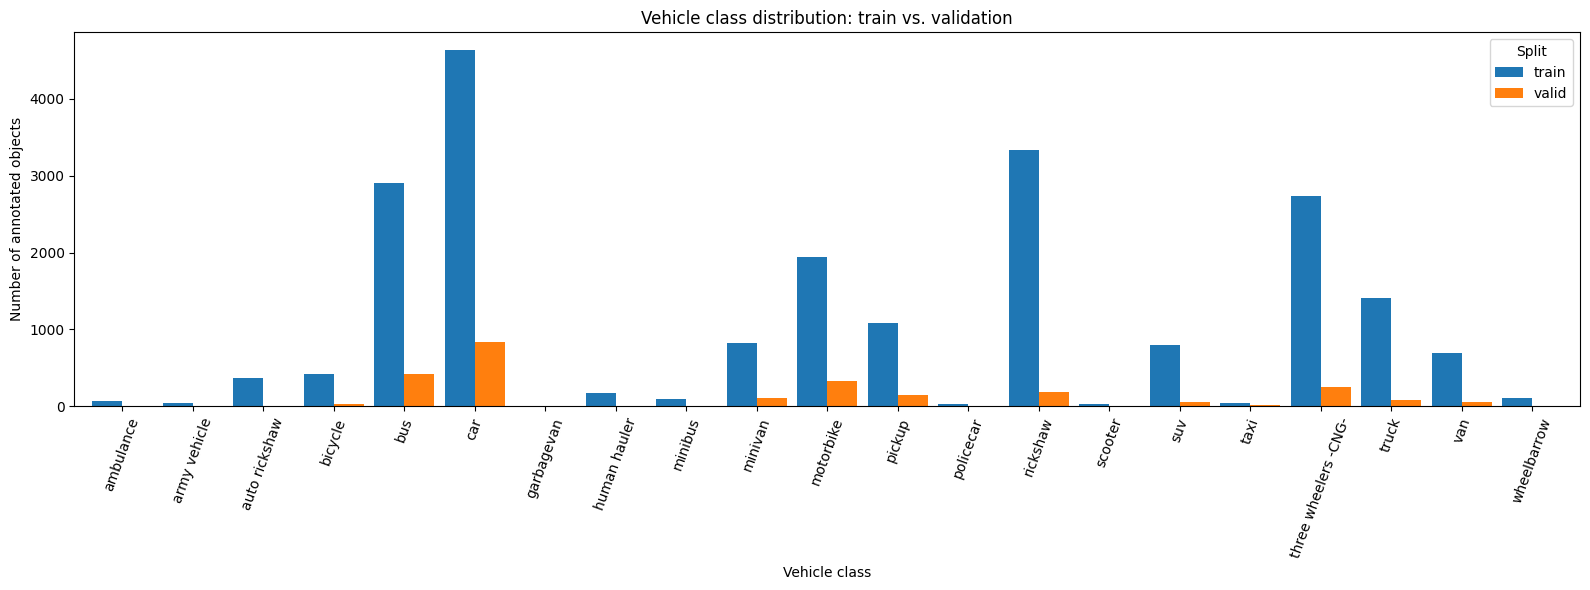

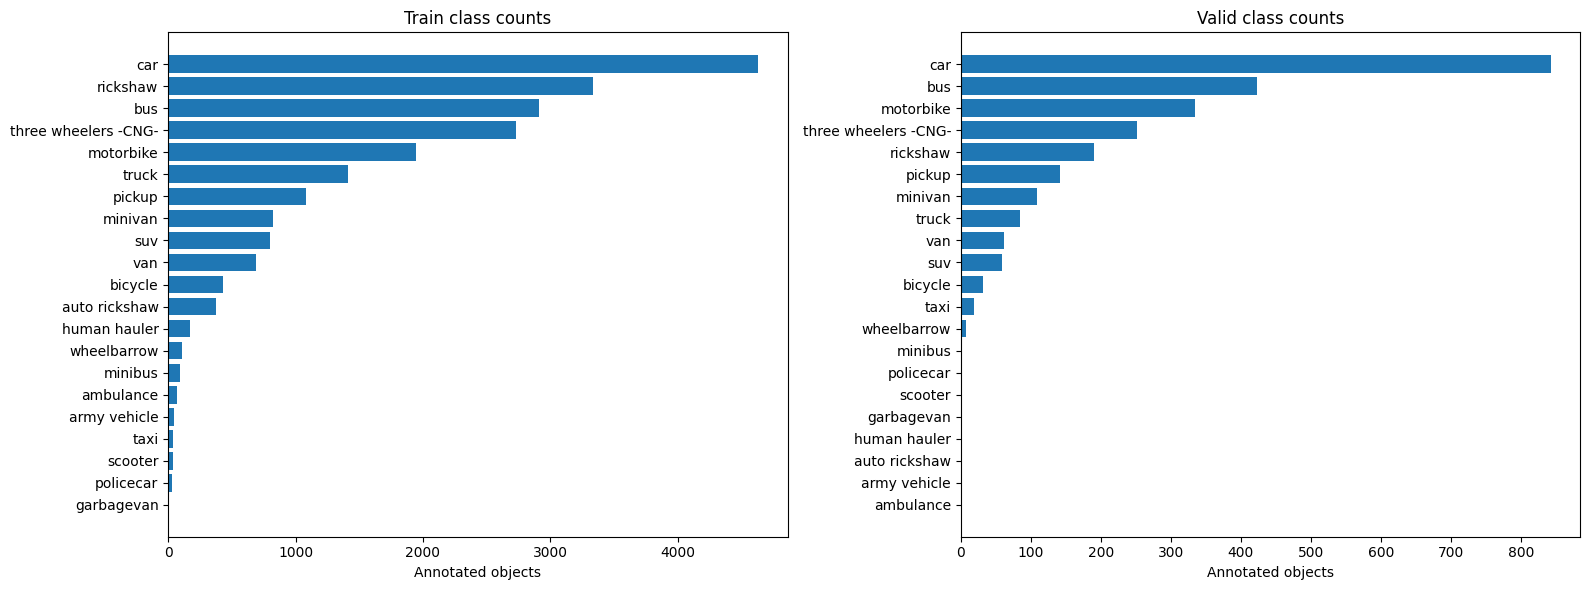

Classes below 1% of the split's annotated objects:


,split,class_name,object_count,percentage
6,train,garbagevan,3,0.013791
12,train,policecar,31,0.142503
14,train,scooter,37,0.170084
16,train,taxi,41,0.188471
1,train,army vehicle,43,0.197665
0,train,ambulance,70,0.321780
8,train,minibus,93,0.427508
20,train,wheelbarrow,111,0.510251
7,train,human hauler,169,0.776869
21,valid,ambulance,0,0.000000


In [5]:
class_index = pd.DataFrame({
    "class_id": range(NC),
    "class_name": CLASS_NAMES,
})

class_counts = (
    annotations_df.groupby(["split", "class_id", "class_name"])
    .size()
    .rename("object_count")
    .reset_index()
)

full_index = pd.MultiIndex.from_product(
    [SPLITS, range(NC)],
    names=["split", "class_id"]
).to_frame(index=False)

full_index["class_name"] = full_index["class_id"].map(
    dict(enumerate(CLASS_NAMES))
)
class_counts = full_index.merge(
    class_counts,
    on=["split", "class_id", "class_name"],
    how="left"
)
class_counts["object_count"] = class_counts["object_count"].fillna(0).astype(int)
class_counts["split_total"] = class_counts.groupby("split")["object_count"].transform("sum")
class_counts["percentage"] = np.where(
    class_counts["split_total"] > 0,
    100 * class_counts["object_count"] / class_counts["split_total"],
    0.0
)

display(class_counts.sort_values(["split", "object_count"], ascending=[True, False]))

counts_pivot = class_counts.pivot(
    index="class_name", columns="split", values="object_count"
).reindex(CLASS_NAMES)

ax = counts_pivot.plot(kind="bar", figsize=(16, 6), width=0.85)
ax.set_title("Vehicle class distribution: train vs. validation")
ax.set_xlabel("Vehicle class")
ax.set_ylabel("Number of annotated objects")
ax.tick_params(axis="x", rotation=70)
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution_train_vs_valid.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, split in zip(axes, SPLITS):
    subset = class_counts[class_counts["split"] == split].sort_values("object_count")
    ax.barh(subset["class_name"], subset["object_count"])
    ax.set_title(f"{split.title()} class counts")
    ax.set_xlabel("Annotated objects")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

rare_threshold = 0.01  # 1% of objects in a split
class_counts["share_fraction"] = class_counts["percentage"] / 100
class_counts["is_rare_by_1pct_rule"] = class_counts["share_fraction"] < rare_threshold

print("Classes below 1% of the split's annotated objects:")
display(
    class_counts[class_counts["is_rare_by_1pct_rule"]][
        ["split", "class_name", "object_count", "percentage"]
    ].sort_values(["split", "percentage"])
)

## 4. Bounding-box size and aspect-ratio analysis

YOLO width and height are normalized by image dimensions. `area = width × height` is therefore a fraction of the image area. Aspect ratio is `width / height`; values below 1 indicate taller boxes and values above 1 indicate wider boxes.


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
width,24314.0,0.095106,0.113254,0.001563,0.007812,0.012500,0.029687,0.056250,0.114062,0.310937,0.587500,0.998437
height,24314.0,0.137814,0.157681,0.004167,0.010937,0.019444,0.044444,0.083333,0.161111,0.466667,0.838528,0.997222
area,24314.0,0.026500,0.071171,0.000007,0.000110,0.000278,0.001396,0.004709,0.017128,0.130669,0.368505,0.981641
aspect_ratio,24314.0,0.808246,0.540662,0.033086,0.173795,0.276007,0.461404,0.662989,0.980055,1.882353,2.765638,8.699722


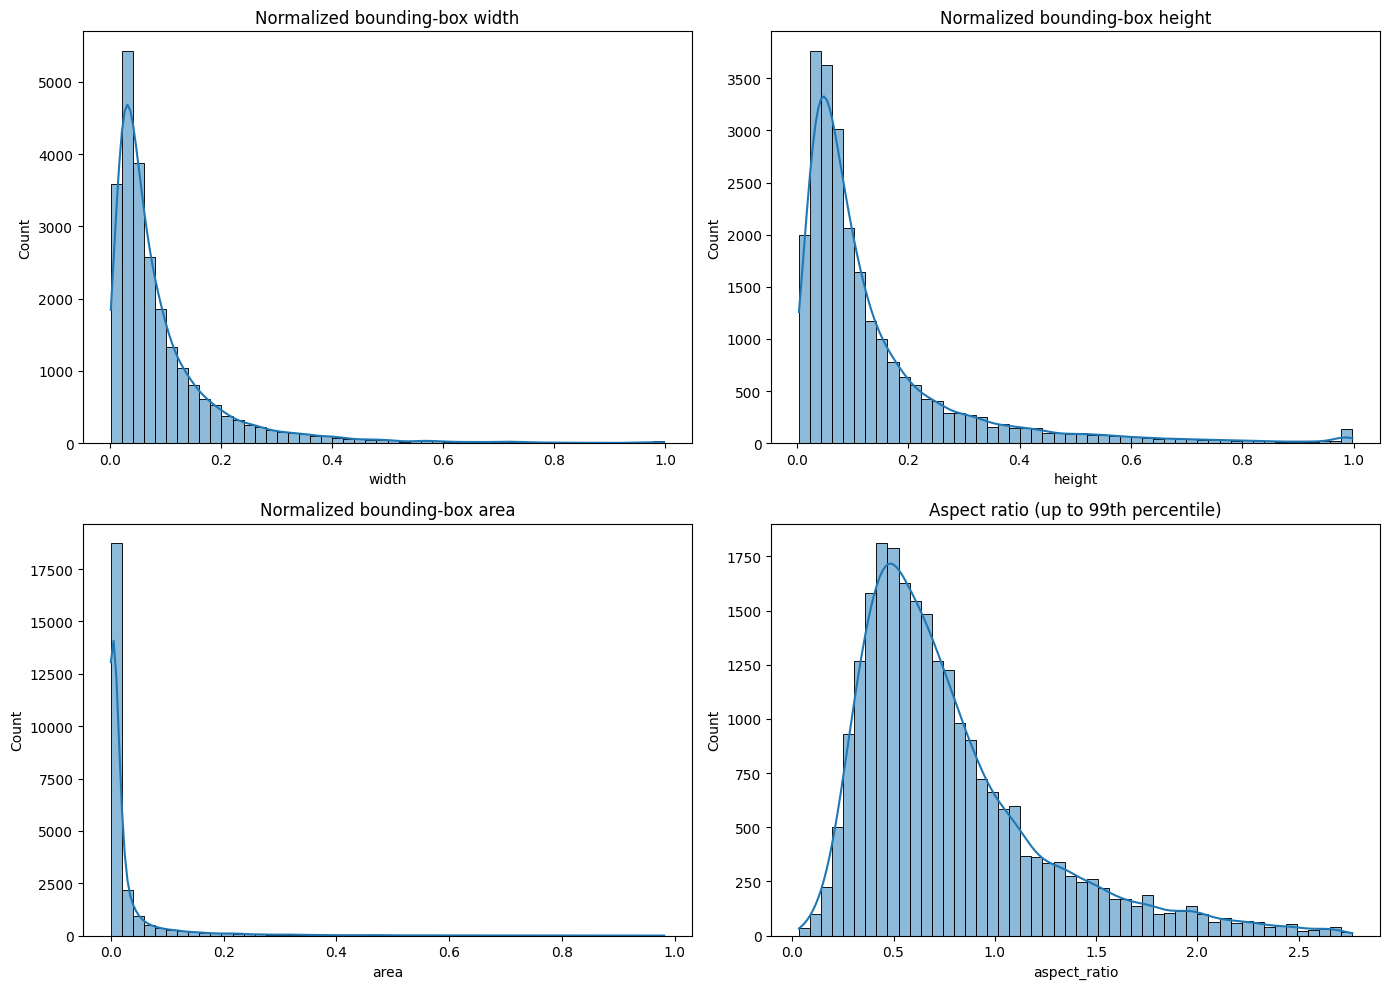

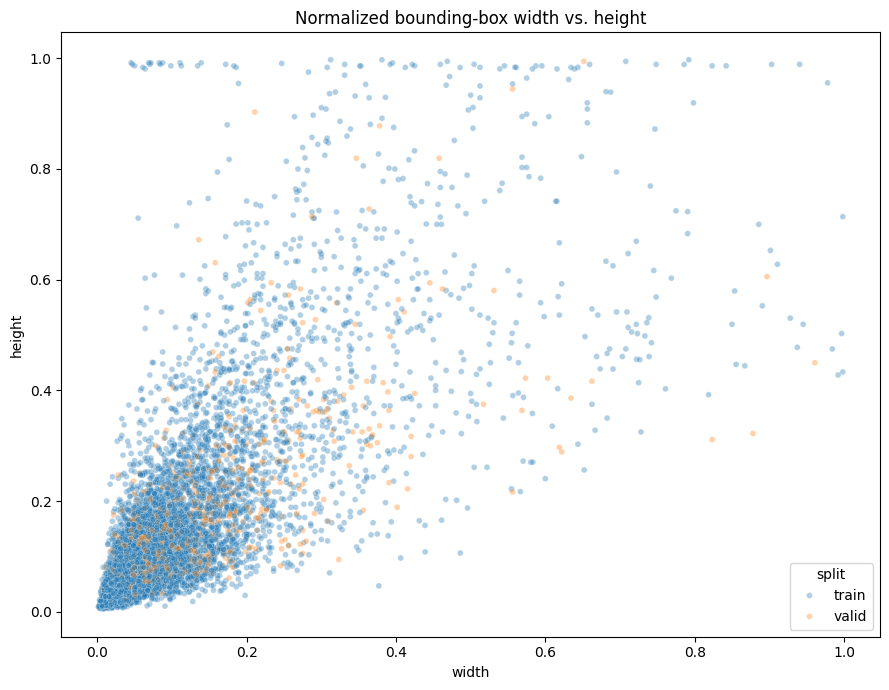

,class_name,width,height,area,aspect_ratio
0,ambulance,0.045312,0.073611,0.003333,0.618946
1,army vehicle,0.092188,0.111111,0.010061,0.836885
2,auto rickshaw,0.035937,0.067685,0.002516,0.500000
3,bicycle,0.031250,0.066667,0.002005,0.436326
4,bus,0.084375,0.108333,0.009330,0.683032
5,car,0.062500,0.069444,0.004297,0.860907
6,garbagevan,0.079687,0.163889,0.013572,0.367786
7,human hauler,0.040625,0.069444,0.002795,0.562506
8,minibus,0.070312,0.080556,0.006406,0.821153
9,minivan,0.062500,0.075000,0.005061,0.750000


In [6]:
if annotations_df.empty:
    print("No valid annotations were parsed; bounding-box analysis is unavailable.")
else:
    box_summary = annotations_df[
        ["width", "height", "area", "aspect_ratio"]
    ].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
    display(box_summary)

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    sns.histplot(data=annotations_df, x="width", bins=50, kde=True, ax=axes[0, 0])
    axes[0, 0].set_title("Normalized bounding-box width")
    sns.histplot(data=annotations_df, x="height", bins=50, kde=True, ax=axes[0, 1])
    axes[0, 1].set_title("Normalized bounding-box height")
    sns.histplot(data=annotations_df, x="area", bins=50, kde=True, ax=axes[1, 0])
    axes[1, 0].set_title("Normalized bounding-box area")
    sns.histplot(
        data=annotations_df[annotations_df["aspect_ratio"] <= annotations_df["aspect_ratio"].quantile(0.99)],
        x="aspect_ratio", bins=50, kde=True, ax=axes[1, 1]
    )
    axes[1, 1].set_title("Aspect ratio (up to 99th percentile)")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "bounding_box_distributions.png", dpi=160, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(9, 7))
    sns.scatterplot(
        data=annotations_df.sample(min(10000, len(annotations_df)), random_state=42),
        x="width", y="height", hue="split", alpha=0.35, s=18
    )
    plt.title("Normalized bounding-box width vs. height")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "bounding_box_width_vs_height.png", dpi=160, bbox_inches="tight")
    plt.show()

    box_by_class = (
        annotations_df.groupby("class_name")[["width", "height", "area", "aspect_ratio"]]
        .median()
        .reindex(CLASS_NAMES)
        .reset_index()
    )
    display(box_by_class)

## 5. Objects per image

This analysis uses every image in the prepared split, including images whose label file is empty. An empty label means zero annotated objects; it is not automatically treated as an error.


,split,image_count,mean_objects,median_objects,max_objects,zero_object_images
0,train,2703,8.048095,5.0,122,2
1,valid,300,8.533333,8.0,24,2


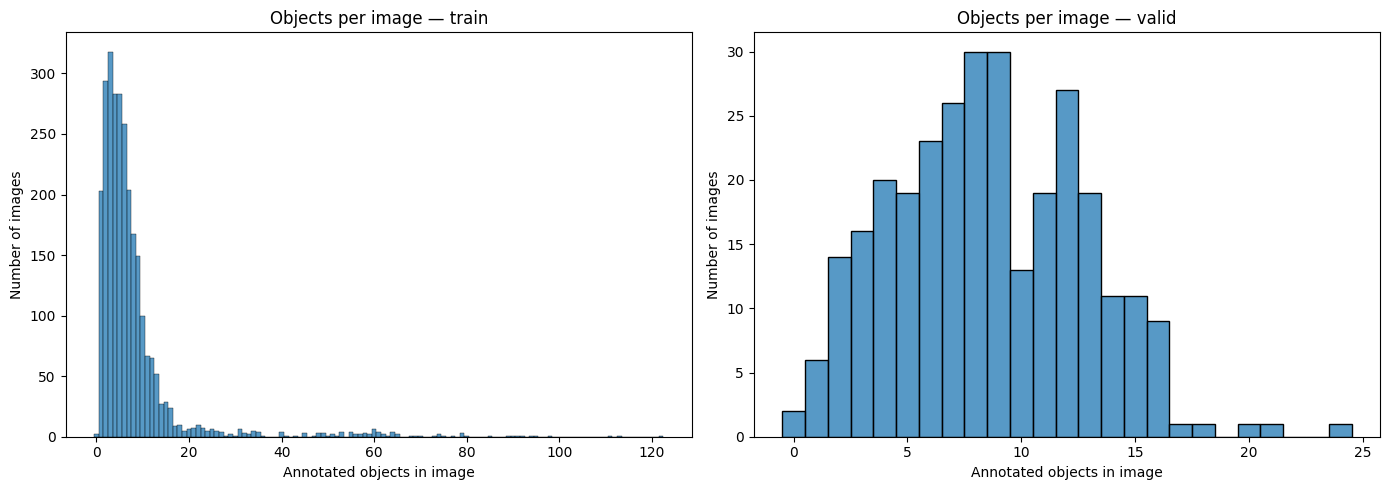

Images with at least 10 annotated objects:


,split,image_name,image_stem,label_file,label_exists,objects_count
134,train,215_jpg.rf.62966bba94843a914cebfd0d695d58ca.jpg,215_jpg.rf.62966bba94843a914cebfd0d695d58ca,215_jpg.rf.62966bba94843a914cebfd0d695d58ca.txt,True,122
135,train,216_jpg.rf.1837651f3201ecc4f709e5c4bfc4ff28.jpg,216_jpg.rf.1837651f3201ecc4f709e5c4bfc4ff28,216_jpg.rf.1837651f3201ecc4f709e5c4bfc4ff28.txt,True,113
201,train,64_jpg.rf.e88dfd8566cbc446c44650ea0b13d8d3.jpg,64_jpg.rf.e88dfd8566cbc446c44650ea0b13d8d3,64_jpg.rf.e88dfd8566cbc446c44650ea0b13d8d3.txt,True,111
215,train,78_jpg.rf.93edbe881bc016825faa8e839f78774c.jpg,78_jpg.rf.93edbe881bc016825faa8e839f78774c,78_jpg.rf.93edbe881bc016825faa8e839f78774c.txt,True,98
217,train,80_jpg.rf.0f3e8464629e6cb01c7a1cdd5b70598b.jpg,80_jpg.rf.0f3e8464629e6cb01c7a1cdd5b70598b,80_jpg.rf.0f3e8464629e6cb01c7a1cdd5b70598b.txt,True,95
211,train,74_jpg.rf.0ce2b7b3e921b7eb184a99d19978161d.jpg,74_jpg.rf.0ce2b7b3e921b7eb184a99d19978161d,74_jpg.rf.0ce2b7b3e921b7eb184a99d19978161d.txt,True,94
140,train,220_jpg.rf.bb4fb2039b30af4430335bc68efea844.jpg,220_jpg.rf.bb4fb2039b30af4430335bc68efea844,220_jpg.rf.bb4fb2039b30af4430335bc68efea844.txt,True,92
137,train,218_jpg.rf.77dae4fa1e4a4bca67b90b5b711bfefa.jpg,218_jpg.rf.77dae4fa1e4a4bca67b90b5b711bfefa,218_jpg.rf.77dae4fa1e4a4bca67b90b5b711bfefa.txt,True,91
234,train,97_jpg.rf.faee5247955bbebc83e6b6b36f993960.jpg,97_jpg.rf.faee5247955bbebc83e6b6b36f993960,97_jpg.rf.faee5247955bbebc83e6b6b36f993960.txt,True,90
129,train,210_jpg.rf.a21ca4b085d84b309708ef8b419a07d8.jpg,210_jpg.rf.a21ca4b085d84b309708ef8b419a07d8,210_jpg.rf.a21ca4b085d84b309708ef8b419a07d8.txt,True,89


In [7]:
objects_summary = (
    images_df.groupby("split")["objects_count"]
    .agg(
        image_count="count",
        mean_objects="mean",
        median_objects="median",
        max_objects="max",
        zero_object_images=lambda s: int((s == 0).sum()),
    )
    .reset_index()
)
display(objects_summary)

fig, axes = plt.subplots(1, len(SPLITS), figsize=(7 * len(SPLITS), 5), squeeze=False)
for ax, split in zip(axes[0], SPLITS):
    subset = images_df.loc[images_df["split"] == split, "objects_count"]
    bins = range(0, int(subset.max()) + 2) if len(subset) and subset.max() > 0 else 10
    sns.histplot(subset, bins=bins, discrete=True, ax=ax)
    ax.set_title(f"Objects per image — {split}")
    ax.set_xlabel("Annotated objects in image")
    ax.set_ylabel("Number of images")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "objects_per_image.png", dpi=160, bbox_inches="tight")
plt.show()

crowded_threshold = 10
crowded_images = images_df[images_df["objects_count"] >= crowded_threshold].sort_values(
    ["split", "objects_count"], ascending=[True, False]
)
print(f"Images with at least {crowded_threshold} annotated objects:")
display(crowded_images.head(20))

## 6. Class imbalance metrics

The metrics below quantify the distribution of annotated objects. They are descriptive indicators, not automatic proof that a particular training strategy is required. Validation classes with very few examples can also make per-class evaluation unstable.


,split,total_objects,classes_with_objects,classes_with_zero_objects,max_class_count,min_positive_class_count,max_to_min_positive_ratio,max_to_mean_ratio,gini_coefficient
0,train,21754,21,0,4630,3,1543.333333,4.469523,0.628719
1,valid,2560,16,5,842,1,842.000000,6.907031,0.719308


,class_id,class_name,total_objects,percentage,relative_to_largest,imbalance_ratio_vs_largest
6,6,garbagevan,3,0.012339,0.000548,1824.000000
12,12,policecar,32,0.131611,0.005848,171.000000
14,14,scooter,38,0.156289,0.006944,144.000000
1,1,army vehicle,43,0.176853,0.007858,127.255814
16,16,taxi,60,0.246771,0.010965,91.200000
0,0,ambulance,70,0.287900,0.012792,78.171429
8,8,minibus,95,0.390721,0.017361,57.600000
20,20,wheelbarrow,119,0.489430,0.021747,45.983193
7,7,human hauler,169,0.695073,0.030885,32.378698
2,2,auto rickshaw,372,1.529983,0.067982,14.709677


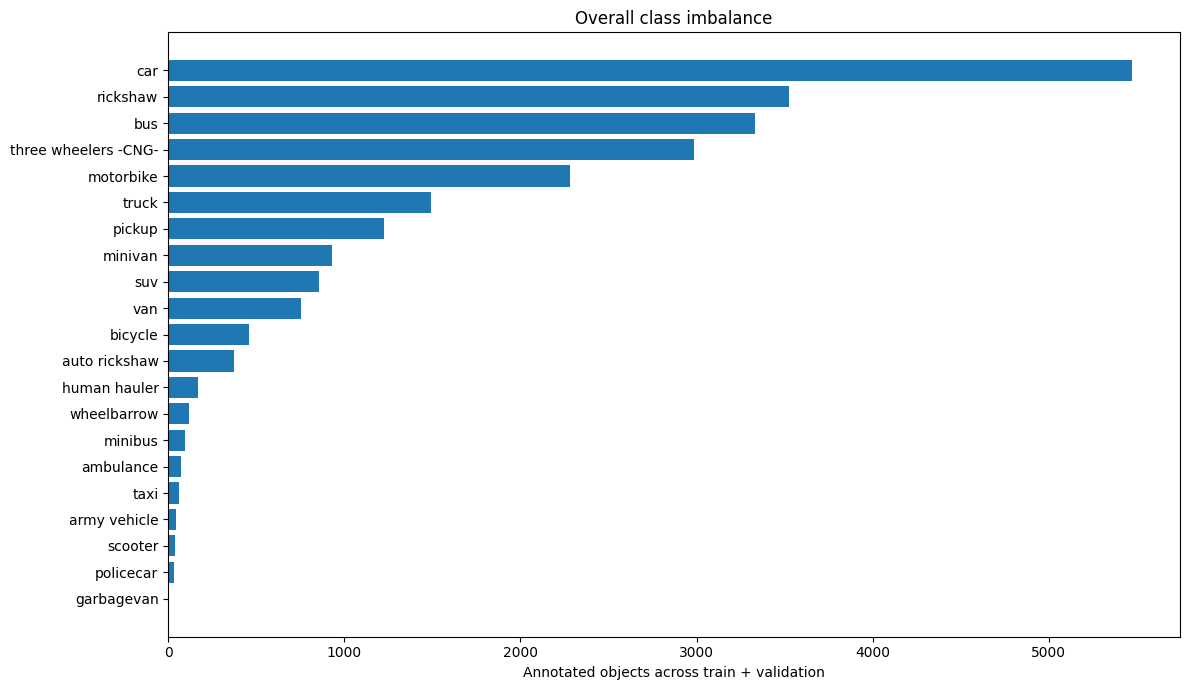

In [8]:
imbalance_rows = []

for split in SPLITS:
    counts = (
        class_counts[class_counts["split"] == split]
        .set_index("class_id")["object_count"]
        .reindex(range(NC), fill_value=0)
    )
    total = int(counts.sum())
    nonzero = counts[counts > 0]

    max_count = int(counts.max()) if len(counts) else 0
    min_positive = int(nonzero.min()) if not nonzero.empty else 0
    mean_count = float(counts.mean()) if len(counts) else 0.0

    # Gini coefficient across all configured classes; 0 means equal counts.
    values = np.sort(counts.to_numpy(dtype=float))
    if total > 0:
        n = len(values)
        gini = (2 * np.sum((np.arange(1, n + 1) * values)) / (n * total)) - ((n + 1) / n)
    else:
        gini = np.nan

    imbalance_rows.append({
        "split": split,
        "total_objects": total,
        "classes_with_objects": int((counts > 0).sum()),
        "classes_with_zero_objects": int((counts == 0).sum()),
        "max_class_count": max_count,
        "min_positive_class_count": min_positive,
        "max_to_min_positive_ratio": (max_count / min_positive) if min_positive else np.nan,
        "max_to_mean_ratio": (max_count / mean_count) if mean_count else np.nan,
        "gini_coefficient": gini,
    })

imbalance_metrics = pd.DataFrame(imbalance_rows)
display(imbalance_metrics)

# Combine splits for an overall view while retaining the split-specific metrics above.
overall_counts = (
    class_counts.groupby(["class_id", "class_name"], as_index=False)["object_count"]
    .sum()
    .rename(columns={"object_count": "total_objects"})
)
overall_total = overall_counts["total_objects"].sum()
overall_counts["percentage"] = (
    100 * overall_counts["total_objects"] / overall_total if overall_total else 0
)
overall_counts["relative_to_largest"] = (
    overall_counts["total_objects"] / overall_counts["total_objects"].max()
    if overall_counts["total_objects"].max() else 0
)
overall_counts["imbalance_ratio_vs_largest"] = np.where(
    overall_counts["total_objects"] > 0,
    overall_counts["total_objects"].max() / overall_counts["total_objects"].replace(0, np.nan),
    np.nan,
)
display(overall_counts.sort_values("total_objects"))

plt.figure(figsize=(12, 7))
plot_data = overall_counts.sort_values("total_objects")
plt.barh(plot_data["class_name"], plot_data["total_objects"])
plt.xlabel("Annotated objects across train + validation")
plt.title("Overall class imbalance")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "overall_class_imbalance.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Save CSV reports and visualizations

All outputs are saved under `roadvision_cleaned/reports/` and `roadvision_cleaned/figures/`. The notebook does not rewrite images or label files.


In [9]:
# Export tables
class_counts.to_csv(REPORT_DIR / "class_distribution_by_split.csv", index=False)
overall_counts.to_csv(REPORT_DIR / "overall_class_distribution.csv", index=False)
box_summary.to_csv(REPORT_DIR / "bounding_box_summary.csv") if not annotations_df.empty else None
box_by_class.to_csv(REPORT_DIR / "bounding_box_summary_by_class.csv", index=False) if not annotations_df.empty else None
images_df.to_csv(REPORT_DIR / "objects_per_image.csv", index=False)
objects_summary.to_csv(REPORT_DIR / "objects_per_image_summary.csv", index=False)
imbalance_metrics.to_csv(REPORT_DIR / "class_imbalance_metrics.csv", index=False)
issues_df.to_csv(REPORT_DIR / "analysis_parsing_issues.csv", index=False)

print("CSV reports saved to:", REPORT_DIR)
print("Figures saved to:", FIGURE_DIR)
print("\nReport files:")
for path in sorted(REPORT_DIR.glob("*.csv")):
    print("-", path.name)
print("\nFigure files:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print("-", path.name)

CSV reports saved to: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/reports
Figures saved to: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/roadvision_cleaned/figures

Report files:
- analysis_parsing_issues.csv
- bounding_box_summary.csv
- bounding_box_summary_by_class.csv
- class_distribution_by_split.csv
- class_imbalance_metrics.csv
- cleaned_class_distribution.csv
- cleaning_actions.csv
- corrupted_images.csv
- duplicate_handling_decisions.csv
- empty_labels_audit.csv
- image_integrity.csv
- invalid_annotation_lines.csv
- objects_per_image.csv
- objects_per_image_summary.csv
- overall_class_distribution.csv
- reconciled_class_distribution.csv

Figure files:
- bounding_box_distributions.png
- bounding_box_width_vs_height.png
- class_distribution_by_split.png
- class_distribution_train_vs_valid.png
- objects_per_image.png
- overall_class_imbalance.png


## 8. Findings and recommendations

Use the computed tables and plots to write evidence-based conclusions. The cell below generates a concise, data-driven summary; review it alongside the plots before adding conclusions to the project report.


In [10]:
print("ROADVISION AI — DATA ANALYSIS SUMMARY")
print("=" * 45)

print(f"Prepared images: {len(images_df):,}")
print(f"Parsed bounding boxes: {len(annotations_df):,}")
print(f"Annotation parsing/integrity issues: {len(issues_df):,}")

for split in SPLITS:
    split_images = images_df[images_df["split"] == split]
    split_boxes = annotations_df[annotations_df["split"] == split]
    print(
        f"{split.upper()}: {len(split_images):,} images, "
        f"{len(split_boxes):,} boxes, "
        f"{(split_images['objects_count'] == 0).sum():,} images with zero objects"
    )

if not overall_counts.empty:
    ranked = overall_counts.sort_values("total_objects", ascending=False)
    print("\nMost frequent classes:")
    for row in ranked.head(5).itertuples():
        print(f"  - {row.class_name}: {row.total_objects:,} ({row.percentage:.2f}%)")

    nonzero = ranked[ranked["total_objects"] > 0]
    print("\nLeast frequent classes with at least one object:")
    for row in nonzero.tail(5).sort_values("total_objects").itertuples():
        print(f"  - {row.class_name}: {row.total_objects:,} ({row.percentage:.2f}%)")

    zero_classes = ranked[ranked["total_objects"] == 0]["class_name"].tolist()
    if zero_classes:
        print("\nClasses with no parsed objects across analyzed splits:", zero_classes)

if not annotations_df.empty:
    print("\nBounding-box medians:")
    print(f"  Width: {annotations_df['width'].median():.4f} of image width")
    print(f"  Height: {annotations_df['height'].median():.4f} of image height")
    print(f"  Area: {annotations_df['area'].median():.6f} of image area")
    print(f"  Aspect ratio: {annotations_df['aspect_ratio'].median():.3f}")

if not objects_summary.empty:
    print("\nObjects per image:")
    for row in objects_summary.itertuples():
        print(
            f"  {row.split}: mean={row.mean_objects:.2f}, "
            f"median={row.median_objects:.0f}, max={row.max_objects}"
        )

print("\nRecommendations to consider after reviewing results:")
print("1. Check rare classes and their validation counts before interpreting per-class metrics.")
print("2. Inspect very small and extreme-aspect-ratio boxes visually to confirm label quality.")
print("3. If imbalance is substantial, consider training-time sampling or class-aware augmentation.")
print("4. Keep the validation set representative; do not move examples based only on desired counts.")
print("5. Use the saved CSVs and plots as evidence in the project report.")

ROADVISION AI — DATA ANALYSIS SUMMARY
Prepared images: 3,003
Parsed bounding boxes: 24,314
Annotation parsing/integrity issues: 0
TRAIN: 2,703 images, 21,754 boxes, 2 images with zero objects
VALID: 300 images, 2,560 boxes, 2 images with zero objects

Most frequent classes:
  - car: 5,472 (22.51%)
  - rickshaw: 3,526 (14.50%)
  - bus: 3,330 (13.70%)
  - three wheelers -CNG-: 2,985 (12.28%)
  - motorbike: 2,283 (9.39%)

Least frequent classes with at least one object:
  - garbagevan: 3 (0.01%)
  - policecar: 32 (0.13%)
  - scooter: 38 (0.16%)
  - army vehicle: 43 (0.18%)
  - taxi: 60 (0.25%)

Bounding-box medians:
  Width: 0.0563 of image width
  Height: 0.0833 of image height
  Area: 0.004709 of image area
  Aspect ratio: 0.663

Objects per image:
  train: mean=8.05, median=5, max=122
  valid: mean=8.53, median=8, max=24

Recommendations to consider after reviewing results:
1. Check rare classes and their validation counts before interpreting per-class metrics.
2. Inspect very small an